# CORTIVA · From EEG to a ranked video list
### A reproducible walkthrough for the jury · final v7

Given a three-second EEG recording, which of 102 videos was the person watching?
We compare EEG and stimulus embeddings, combine complementary models, and use the
known one-recording-per-video structure to produce a complete ranking.

> **Start here:** select a Python 3.11 kernel and choose **Run All**. The default
> path needs no raw challenge data, GPU, model downloads, or training. It verifies
> the payload, reproduces the submission, and recalculates decision plots from
> packaged training-holdout scores. The figures below are generated by these cells.

Install the lightweight notebook environment from the repository root:
```sh
python -m pip install -r requirements-notebook.txt
python -m jupyterlab JURY_WALKTHROUGH.ipynb
```

**Reading route:** task and recipe → exact replay → validation protocol → family
complementarity → audio/video weights → ranking → training settings → DEV results
→ optional inference and retraining. Every executable block has an explanation.

> **Evidence key:** “recomputed” means calculated now from shipped scores;
> “recorded” means a saved experiment result; “fixed” means an engineering choice.
> The reused validation split and repeatedly inspected DEV are not blind tests.
> Performance on blind subjects sub-05/06 remains unknown.


## Where are the final matrices for jury evaluation?

We write two integer **102 × 102 ranking matrices** for the withheld subjects:
`sub-05_ranked_candidate_list.npy` and `sub-06_ranked_candidate_list.npy`.
The directory depends on which execution path you run:

| Execution path | Directory containing both `.npy` files |
|---|---|
| Default Run All: exact replay of saved scores | `outputs/jury/replay/` |
| Section 9: `RUN_INFERENCE=True`, models applied to raw EEG | `outputs/jury/infer/` |
| Section 10: `RUN_TRAINING=True`, internal refit then inference | `outputs/jury/train/` |
| Section 11: audio/video retraining switches, then inference | `outputs/jury/retrain-external/` |
| Already packaged locked predictions | `predictions/` |

For a model execution against the official test EEG, set `DATA_ROOT` and enable
the inference cell in section 9. The default Run All path needs no raw data and
recreates our locked matrices from scores. Optional folders are only created
when their corresponding cells are enabled and executed.

After a successful inference run, the files to evaluate are:
```text
outputs/jury/infer/sub-05_ranked_candidate_list.npy
outputs/jury/infer/sub-06_ranked_candidate_list.npy
```

Row `i` corresponds to row `i` in the respective subject's `tst/sub-XX_tst.npy`.
Column `j` contains the video ID at rank `j + 1`, so column 0 is our first choice.
Every row contains all IDs 1001–1102 once. These are ranked IDs, not similarity
scores or probabilities. We preserve the original recording order.

Each completed run also writes `submission.zip`, containing exactly these two
arrays, and `run.json`, containing metadata and differences from our locked
predictions. You evaluate the arrays against your withheld sub-05/06 labels;
our program does not read or need those labels. Wait for successful completion
before evaluating the output folder. CLI output paths are listed in
[README.md](README.md#generate-the-matrices-for-jury-evaluation).


In [1]:
from pathlib import Path
import sys, json, subprocess, importlib.util, html
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, HTML
%matplotlib inline

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "config/final.json").is_file() and (p / "verify_release.py").is_file()), None)
if ROOT is None:
    raise RuntimeError("Open this notebook from the extracted final-v7 repository.")
OUT = ROOT / "outputs/jury"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
def read_json(relative):
    return json.loads((ROOT / relative).read_text(encoding="utf-8"))
def run_script(relative, *args):
    subprocess.run([sys.executable, str(ROOT / relative), *map(str, args)], cwd=ROOT, check=True)
def table(headers, rows):
    def row(values, tag):
        return "<tr>" + "".join(f"<{tag}>{html.escape(str(v))}</{tag}>" for v in values) + "</tr>"
    display(HTML("<table>" + row(headers, "th") + "".join(row(r, "td") for r in rows) + "</table>"))
plt.rcParams.update({"figure.figsize": (10, 4), "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": .18, "font.size": 11, "figure.dpi": 115})
BLUE, ORANGE, GREEN = "#24638a", "#c46a2f", "#35816a"
config = read_json("config/final.json")
print("Python:", sys.version.split()[0], "| NumPy:", np.__version__)
print("Default mode: packaged evidence and exact replay; outputs:", OUT.relative_to(ROOT))


Python: 3.11.9 | NumPy: 2.2.6
Default mode: packaged evidence and exact replay; outputs: outputs\jury


## 1 · What is learned, and what is combined?

The internal dual encoder learns to align the matching EEG/video pair in a shared
embedding space. Its contrastive objective uses multiple subjects watching the
same video as positives. A shared and subject-specific spatial projection models
the six known subjects; this is not a zero-shot-subject result.

EEG is filtered to the configured low-frequency band and resampled from 500 to
50 Hz. Three seconds × 50 Hz gives 150 time points across 17 channels. Unlabelled
set-mean removal and channel scaling are applied separately to each set.
Stimulus features combine public audio/visual encoders with low-level features;
PCA and feature scaling are fitted on training videos only.

Five feature families and twelve seeds per family form the internal ensemble.
Row z-scoring makes scores comparable before averaging seeds, families, and then
the three model groups. The table reads the actual frozen recipe.


Family,Seeds,Stimulus feature recipe
G-whisper32,12,"{""lowlevel"": ""full"", ""pca"": 32, ""visual"": [{""k"": 16, ""model"": ""dinov2-base""}], ""whisper_layers"": [2, 3, 4]}"
O-whisper32-audiorich,12,"{""audio_rich"": true, ""lowlevel"": ""full"", ""pca"": 32, ""visual"": [{""k"": 16, ""model"": ""dinov2-base""}], ""whisper_layers"": [2, 3, 4]}"
D-clip,12,"{""lowlevel"": ""full"", ""pca"": 64, ""visual"": [{""k"": 16, ""model"": ""dinov2-base""}, {""k"": 16, ""model"": ""clip-b32""}], ""whisper_layers"": [2, 3, 4]}"
H-lowvisual,12,"{""lowlevel"": ""visual"", ""pca"": 64, ""visual"": [{""k"": 16, ""model"": ""dinov2-base""}], ""whisper_layers"": [2, 3, 4]}"
I-audiorich,12,"{""audio_rich"": true, ""lowlevel"": ""full"", ""pca"": 64, ""visual"": [{""k"": 16, ""model"": ""dinov2-base""}], ""whisper_layers"": [2, 3, 4]}"


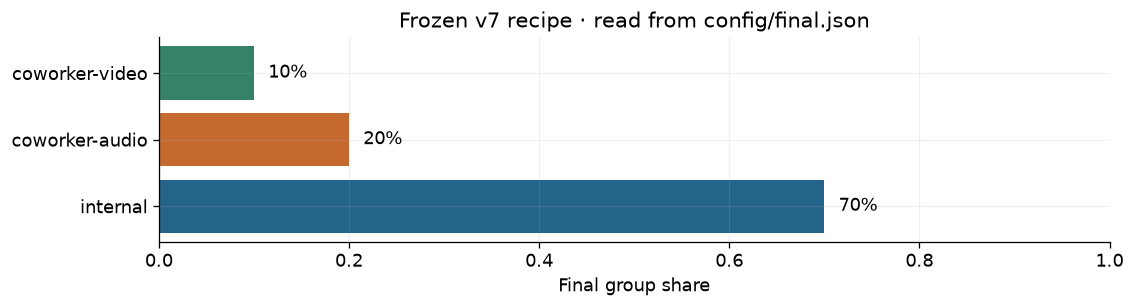

Internal members: 60 | EEG band: [0.2, 12.0] Hz


In [2]:
table(["Family", "Seeds", "Stimulus feature recipe"],
      [(f["name"], len(f["seeds"]), json.dumps(f["features"], sort_keys=True)) for f in config["families"]])
weights = config["group_weights"]
fig, ax = plt.subplots(figsize=(10, 2.8))
ax.barh(list(weights), list(weights.values()), color=[BLUE, ORANGE, GREEN])
ax.set(xlim=(0, 1), xlabel="Final group share", title="Frozen v7 recipe · read from config/final.json")
for i, value in enumerate(weights.values()):
    ax.text(value + .015, i, f"{value:.0%}", va="center")
plt.tight_layout(); plt.show()
print("Internal members:", sum(len(f["seeds"]) for f in config["families"]), "| EEG band:", config["band"], "Hz")


## 2 · Reproduce the exact submission first

This runs the existing release verifier, reconstructs fusion, checks packaged
file hashes and rankings, and replays the frozen scores into a new output folder.
Replay asserts equality with all six locked arrays and byte equality with the
submission ZIP. It tests score-to-submission reproduction, not model training.

> Re-running and saving this notebook changes its own file. The verifier below
> therefore checks the immutable payload first and verifies every *other* file;
> the original distributed notebook remains covered by the release manifest.


In [3]:
# Reuse all numerical checks; exclude only this intentionally editable notebook.
spec = importlib.util.spec_from_file_location("jury_verifier", ROOT / "verify_release.py")
verifier = importlib.util.module_from_spec(spec)
spec.loader.exec_module(verifier)
verifier.main(editable_notebook=True)
run_script("scripts/final_v7.py", "replay", "--output", OUT / "replay")
replay = read_json("outputs/jury/replay/run.json")
table(["Subject", "Changed Top-1", "Changed ranking entries"],
      [(s, r["top1_changes"], r["ranking_entries_changed"]) for s, r in replay["versus_locked_predictions"].items()])


OK: 160 payload hashes; final fusion, six rankings, and locked ZIP reproduced
Editable walkthrough excluded from hash check; standalone verify_release.py checks it too.


Subject,Changed Top-1,Changed ranking entries
sub-01,0,0
sub-02,0,0
sub-03,0,0
sub-04,0,0
sub-05,0,0
sub-06,0,0


## 3 · Where do the selection numbers come from?

We held out 150 training video IDs using random seed 17 and fitted on the other
850. Each subject has only a subset of recordings, so available candidate counts
differ. These choices fixed reproducibility and compute cost; seed 17 has no
scientific significance. Metrics are averaged equally across subjects.

**Top-1** is the fraction ranked first; **Top-5** is the fraction in the first five;
**MRR** averages 1/(rank of the correct video). Higher is better for all three.
The following audit reruns both family searches and the recorded fusion/ranking
comparisons from training-holdout scores, asserting agreement with saved results.

> This is a fresh evaluation of saved model scores, not fresh model fitting.
> Internal validation used six seeds per family; external validation used four.
> The final internal ensemble uses twelve. The reused holdout supports comparisons,
> not an unbiased forecast of blind performance.


Subject,Validation queries,Available candidates
sub-01,147,147
sub-02,148,148
sub-03,149,149
sub-04,143,143
sub-05,144,144
sub-06,124,124


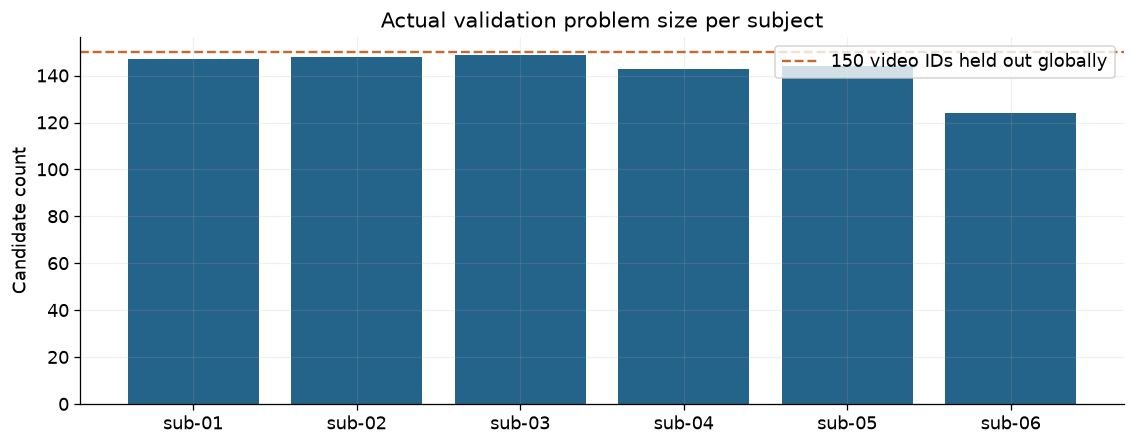

In [4]:
run_script("scripts/audit_decisions.py", "--output", OUT / "decision-audit.json")
audit = read_json("outputs/jury/decision-audit.json")
table(["Subject", "Validation queries", "Available candidates"],
      [(s, audit["query_counts"][s], audit["candidate_counts"][s]) for s in config["subjects"]])
fig, ax = plt.subplots()
ax.bar(list(audit["candidate_counts"]), list(audit["candidate_counts"].values()), color=BLUE)
ax.axhline(150, ls="--", color=ORANGE, label="150 video IDs held out globally")
ax.set(ylabel="Candidate count", title="Actual validation problem size per subject")
ax.legend(); plt.tight_layout(); plt.show()


## 4 · Why keep several feature families?

Complementary errors can make an ensemble better than its strongest single model.
The left plot reconstructs the two original greedy forward searches. The final
G/O/D/H/I set was a curated union with dependency pruning, not the output of one
automatic optimisation. The HuBERT extension brought only a small reported MRR
gain and added a model dependency; its exclusion was an engineering tradeoff.

The right plot removes one final family at a time. Positive change means removing
it helped on this validation set. In particular, removing I slightly improves MRR:
the five-family choice is not a leave-one-out optimum. Equal family weights are
a fixed averaging rule to avoid another weight search.


family-select · added family,Recomputed MRR
G-w32-splice,0.380129
H-lowvis-splice,0.391370
I-arich-splice,0.399169


family-select-extra · added family,Recomputed MRR
G-w32-splice,0.380129
O-w32-arich,0.391393
D-clip-splice,0.399108
H-lowvis-splice,0.400127
F-hubert-splice,0.400894


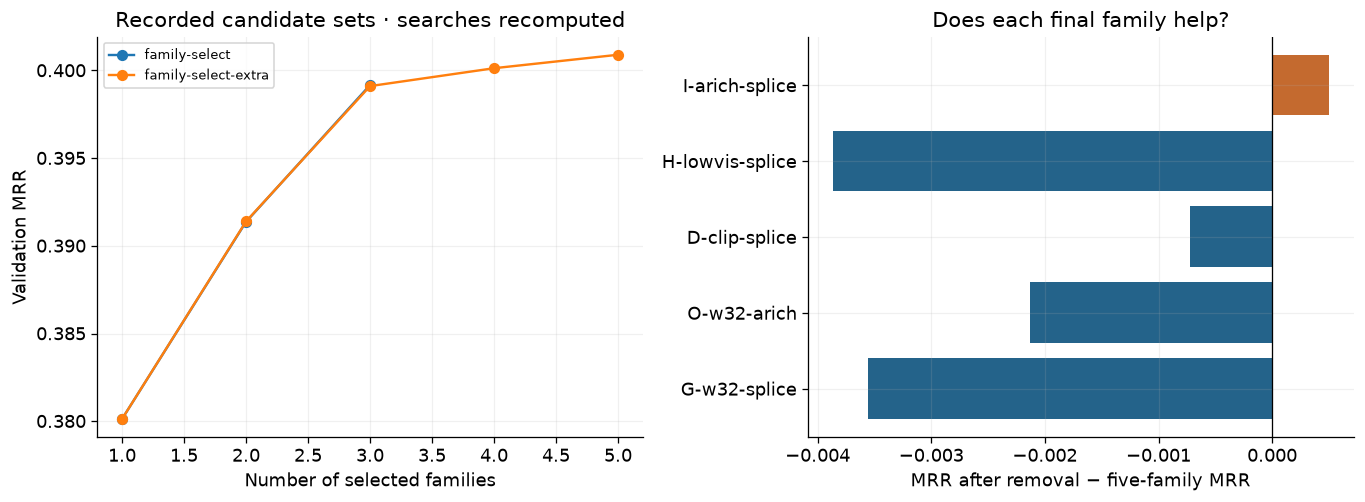

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for name, steps in audit["family_greedy_searches"].items():
    axes[0].plot(range(1, len(steps)+1), [r["mrr"] for r in steps], "o-", label=name)
    table([name + " · added family", "Recomputed MRR"], [(r["added"], f'{r["mrr"]:.6f}') for r in steps])
axes[0].set(xlabel="Number of selected families", ylabel="Validation MRR", title="Recorded candidate sets · searches recomputed")
axes[0].legend(fontsize=8)
loo = audit["final_internal_leave_one_out"]
deltas = [r["mrr"] - audit["final_internal"]["mrr"] for r in loo.values()]
axes[1].barh(list(loo), deltas, color=[ORANGE if d > 0 else BLUE for d in deltas])
axes[1].axvline(0, color="black", lw=.8)
axes[1].set(xlabel="MRR after removal − five-family MRR", title="Does each final family help?")
plt.tight_layout(); plt.show()


## 5 · Why 20% audio and 10% video?

Weights were selected sequentially using independent-ranking holdout MRR:
first vary audio share against the internal ensemble; then keep audio fixed and
vary video share, leaving the remainder for internal models. The selected points
below come from the recomputed audit and must agree with the frozen config.

Close neighbouring values show that the exact decimals are not sharply established
optima. This was a finite sequential grid, not an exhaustive joint search or a
statistical significance test. Video weight 0.05 gives a different assigned Top-1
optimum; we preserve the declared MRR selection objective.


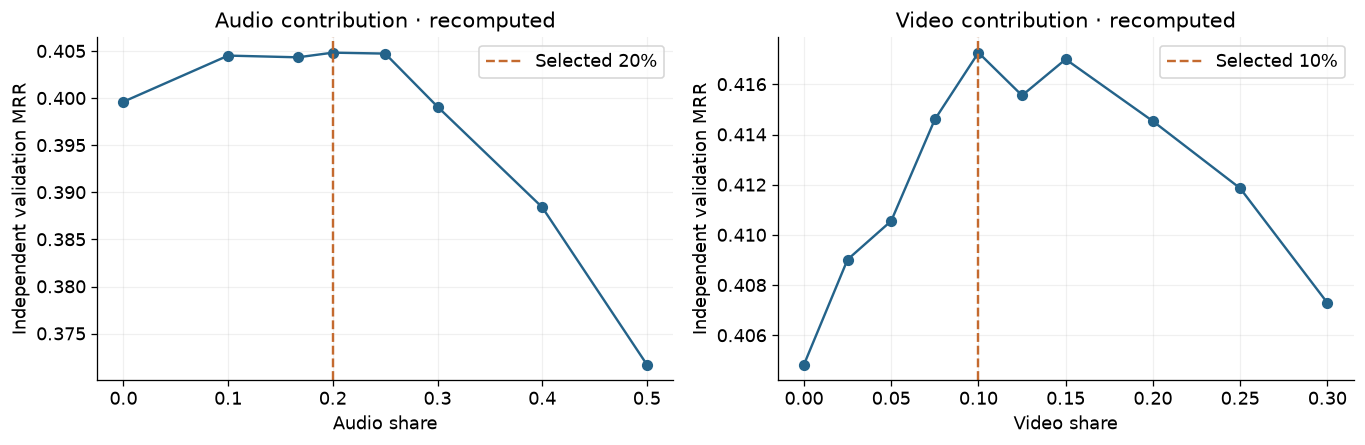

Frozen decision,Recomputed value
audio,0.2
video,0.1
internal,0.7
csls_k,1


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, kind in zip(axes, ("audio", "video")):
    curve = audit[kind + "_curve"]
    keys = sorted(curve, key=float)
    values = [curve[k]["mrr"] if kind == "audio" else curve[k]["independent"]["mrr"] for k in keys]
    ax.plot([float(k) for k in keys], values, "o-", color=BLUE)
    chosen = audit["selected"][kind]
    ax.axvline(chosen, ls="--", color=ORANGE, label=f"Selected {chosen:.0%}")
    ax.set(xlabel=f"{kind.title()} share", ylabel="Independent validation MRR", title=f"{kind.title()} contribution · recomputed")
    ax.legend()
plt.tight_layout(); plt.show()
table(["Frozen decision", "Recomputed value"], audit["selected"].items())


## 6 · Why CSLS and global assignment?

Independent ranking lets multiple recordings choose the same video. Hungarian
assignment maximises the total score subject to one first-choice video per query
and one query per video, using the task's known structure and recorded permission.
The assigned video is placed first, followed by all remaining candidates in stable
descending CSLS order. No labels are used for assignment.

CSLS adjusts a pair score by subtracting local row/column neighbourhood averages.
For a square one-to-one assignment those penalties add a constant to the total
objective, so CSLS cannot explain a separate Hungarian Top-1 gain. It affects
the remaining ranks. The k grid is compared by Top-1, then Top-5, then MRR, rounded
to 12 decimals to prevent numerical noise breaking a mathematical tie.

> **Mixed evidence:** final-mix validation Top-1 decreases with assignment, while
> observed DEV Top-1 improves. This structural choice has no guaranteed blind gain.


CSLS k,Top-1,Top-5,MRR
1,0.291504,0.582453,0.425703
5,0.291504,0.564625,0.423793
10,0.291504,0.562488,0.423280
20,0.291504,0.561542,0.421812


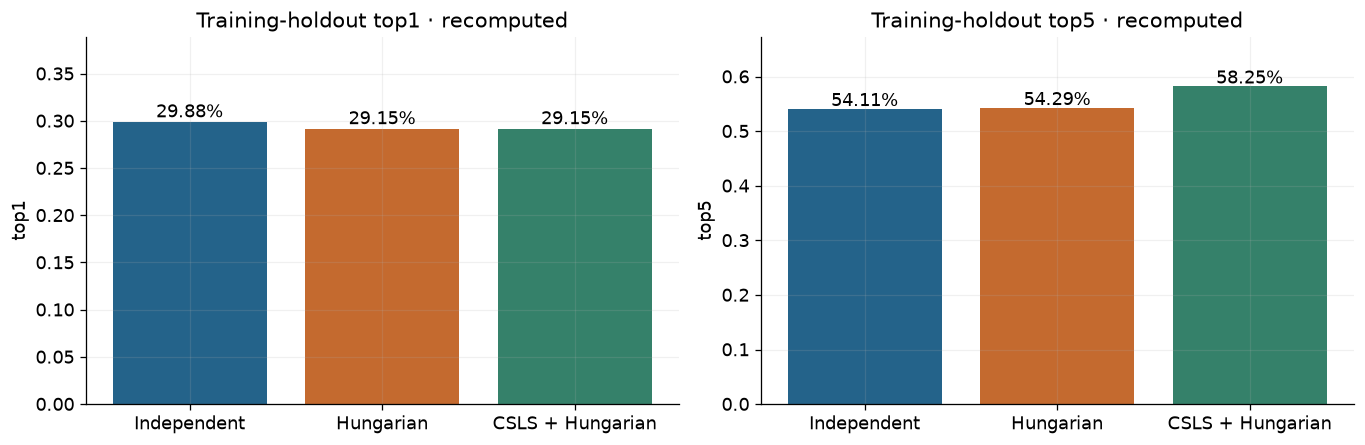

In [7]:
ks = sorted(audit["csls_curve"], key=int)
table(["CSLS k", "Top-1", "Top-5", "MRR"],
      [(k, *[f'{audit["csls_curve"][k][m]:.6f}' for m in ("top1", "top5", "mrr")]) for k in ks])
routes = {"Independent": audit["independent"], "Hungarian": audit["hungarian_without_csls"],
          "CSLS + Hungarian": audit["csls_curve"][str(config["csls_k"]) ]}
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ("top1", "top5")):
    vals = [r[metric] for r in routes.values()]
    ax.bar(list(routes), vals, color=[BLUE, ORANGE, GREEN])
    for i, value in enumerate(vals):
        ax.text(i, value + .005, f"{value:.2%}", ha="center")
    ax.set(ylim=(0, max(vals)+.09), ylabel=metric, title=f"Training-holdout {metric} · recomputed")
plt.tight_layout(); plt.show()


## 7 · Training parameters: evidence versus fixed settings

The table exposes every resolved internal training field, including whether it
varies across final families. The historical sweep scatter shows recorded MRR
against learning rate, input dropout, splice probability, and stopping epoch.
Each point is a whole tested configuration; other fields may change too.

> These are recorded experiments, not reruns or controlled one-factor causal
> comparisons. Missing fields mean that a parameter was not explicitly recorded
> in that row; we do not invent its historical default. The best historical point
> is not automatically the selected final recipe.

The final schedule horizon is 30 epochs but training stops at 22; both matter for
OneCycle. Multi-positive batches group 16 videos, making `batch=256` inactive.
Splicing joins EEG/stimulus segments as augmentation. The fixed 0.6–2.4 s interval
leaves useful segments on either side, rather than asserting a physiological law.
Architecture widths/kernels, weight decay, clipping, temperature and stabilising
epsilons are engineering choices unless supported by an explicit comparison.
See [DECISIONS.md](DECISIONS.md) for the detailed parameter ledger, including
supplier-controlled external settings and all evidence limits.


Parameter,Resolved final values,Evidence status
batch,256,Inactive with multipos=16
blocks,4,Architecture/engineering setting; not an isolated optimum
dropout,0.5,Explored in recorded sweeps
eeg_kernel,9,Architecture/engineering setting; not an isolated optimum
epochs,30,Schedule horizon; tested as part of recipe
extra,{},Resolved optional settings
hidden,128,Architecture/engineering setting; not an isolated optimum
in_dropout,0.5,Explored in recorded sweeps
kernel,5,Architecture/engineering setting; not an isolated optimum
latent,32,Architecture/engineering setting; not an isolated optimum


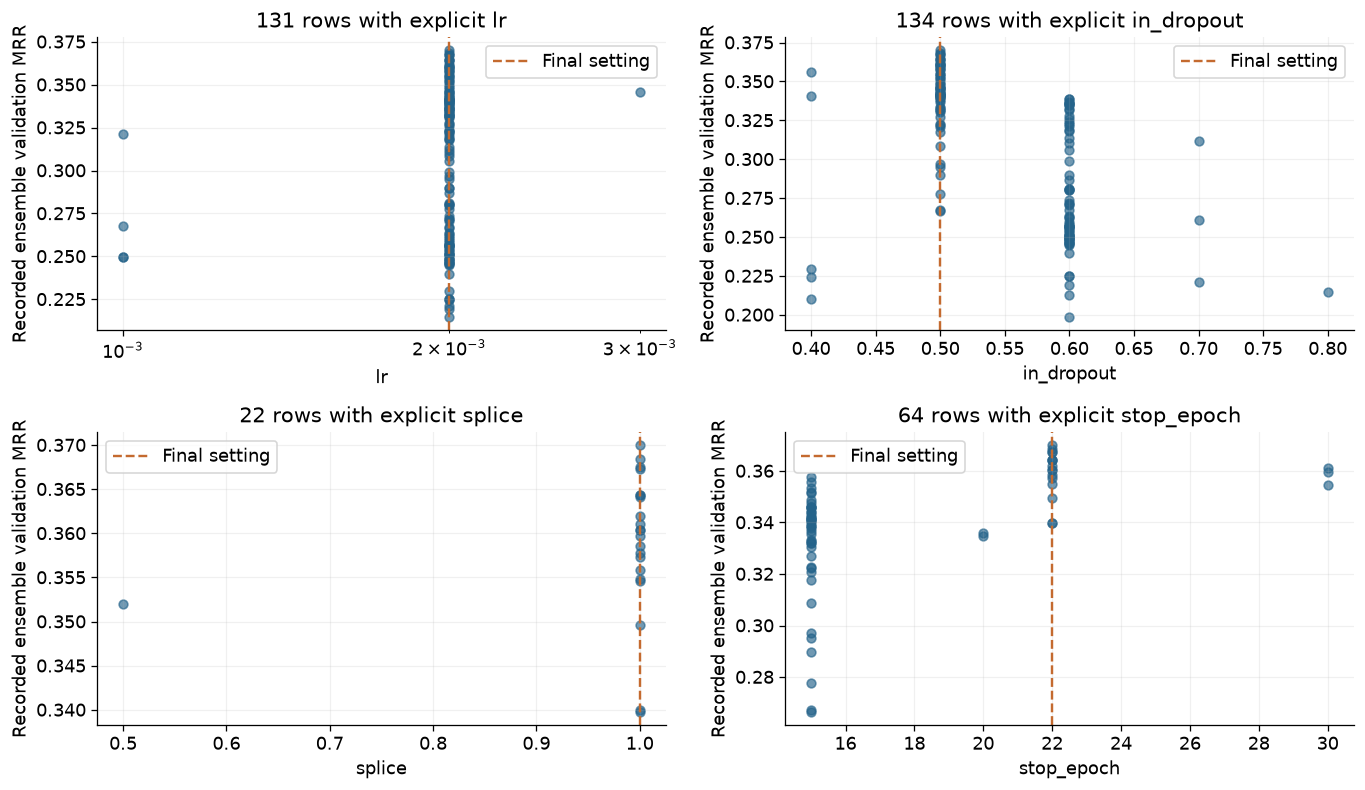

In [8]:
status = {
    "lr": "Explored in recorded sweeps", "dropout": "Explored in recorded sweeps",
    "in_dropout": "Explored in recorded sweeps", "splice": "Explored in recorded sweeps",
    "noise": "Explored in recorded sweeps", "multipos": "Batch/objective exploration",
    "epochs": "Schedule horizon; tested as part of recipe", "stop_epoch": "Stopping rule; tested as part of recipe",
    "batch": "Inactive with multipos=16", "extra": "Resolved optional settings",
}
fields = sorted(set().union(*(f["config"] for f in config["families"])))
table(["Parameter", "Resolved final values", "Evidence status"],
      [(key, "; ".join(sorted({json.dumps(f["config"].get(key), sort_keys=True) for f in config["families"]})),
        status.get(key, "Architecture/engineering setting; not an isolated optimum")) for key in fields])
ablations = read_json("validation/ablations.json")
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for ax, parameter in zip(axes.flat, ("lr", "in_dropout", "splice", "stop_epoch")):
    # Earlier sweeps stored augmentation parameters inside extra, not at top level.
    def recorded_value(row):
        cfg = row["config"]
        return cfg.get(parameter, cfg.get("extra", {}).get(parameter))
    rows = [r for r in ablations if isinstance(recorded_value(r), (int, float))]
    ax.scatter([recorded_value(r) for r in rows], [r["holdout_ensemble_mrr"] for r in rows],
               alpha=.65, s=30, color=BLUE)
    final_values = sorted({f["config"][parameter] for f in config["families"]})
    for i, value in enumerate(final_values):
        ax.axvline(value, color=ORANGE, ls="--", label="Final setting" if i == 0 else None)
    if parameter == "lr":
        ax.set_xscale("log")
    ax.set(xlabel=parameter, ylabel="Recorded ensemble validation MRR", title=f"{len(rows)} rows with explicit {parameter}")
    ax.legend()
plt.tight_layout(); plt.show()


## 8 · What did the final development evaluation show?

The next chart displays **recorded** DEV metrics for sub-01 through sub-04.
Test labels are deliberately absent from this release, so this cell cannot
re-evaluate correctness. The replay above recomputes rankings, whereas this chart
reads the saved evaluation report. DEV was repeatedly inspected during development.
Do not compare its absolute values directly with the different training-holdout
task or treat it as a blind estimate. There are no accuracy bars for sub-05/06.


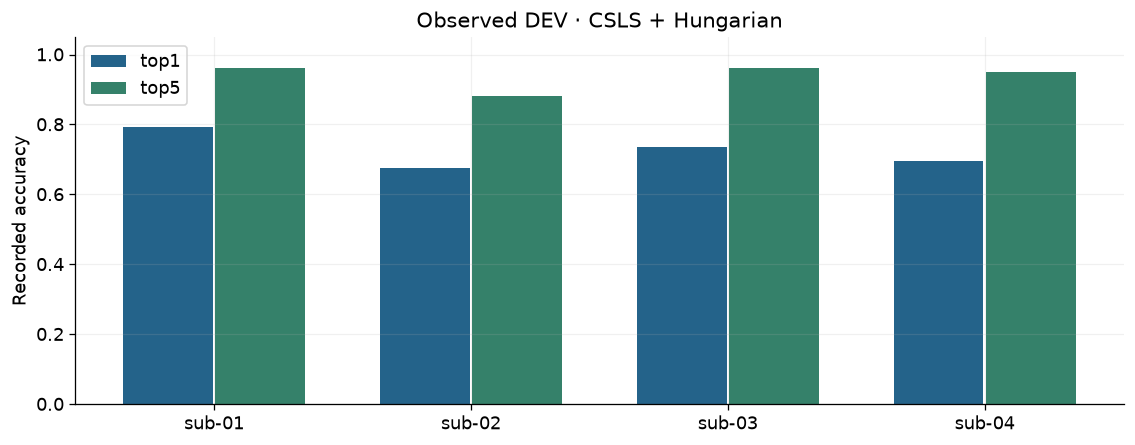

**Recorded DEV:** Top-1 72.55% (296/408); Top-5 93.87%; MRR 0.819577. **Blind accuracy: unknown.**

In [9]:
dev = read_json("predictions/metrics.json")
subjects = list(dev["csls1_hungarian"])
x = np.arange(len(subjects))
fig, ax = plt.subplots()
for offset, metric, color in [(-.18, "top1", BLUE), (.18, "top5", GREEN)]:
    ax.bar(x + offset, [dev["csls1_hungarian"][s][metric] for s in subjects], .35, label=metric, color=color)
ax.set(xticks=x, xticklabels=subjects, ylim=(0, 1.05), ylabel="Recorded accuracy", title="Observed DEV · CSLS + Hungarian")
ax.legend(); plt.tight_layout(); plt.show()
pooled = dev["csls1_hungarian_pooled"]
display(Markdown(f'**Recorded DEV:** Top-1 {pooled["top1"]:.2%} ({pooled["top1_hits"]}/{pooled["queries"]}); '
                 f'Top-5 {pooled["top5"]:.2%}; MRR {pooled["mrr"]:.6f}. **Blind accuracy: unknown.**'))


## 9 · Optional: infer from the saved weights

This is the raw-data-to-predictions route. Install `requirements.txt` in a Python
3.11 environment with the appropriate PyTorch build, select its kernel, and provide
the challenge directory containing `trn/`, `tst/`, `stimuli_train/`, `stimuli_test/`.
Set the switch below to `True` and choose `cuda` or `cpu`. Public encoders may need
downloads; media feature extraction and 60 internal models make this substantially
heavier than replay. No runtime guarantee is made for the jury's hardware.

The CLI does not read `tst_stim/`. Outputs and caches go to `outputs/jury/`.
Numerical variation across hardware can affect lower ranks. The prior checked
GPU run preserved all six Top-1 assignments but changed some lower ranks; see
`validation/weight_reproduction.json`. This cell reports its own new comparison.


In [10]:
RUN_INFERENCE = False
DATA_ROOT = None  # Example: Path("/path/to/challenge")
DEVICE = "cuda"  # Set "cpu" when appropriate for the installed torch build.
if RUN_INFERENCE:
    if DATA_ROOT is None:
        raise ValueError("Set DATA_ROOT before enabling inference.")
    data_root = Path(DATA_ROOT).expanduser().resolve()
    for folder in ("trn", "tst", "stimuli_train", "stimuli_test"):
        if not (data_root / folder).is_dir():
            raise FileNotFoundError(data_root / folder)
    run_script("scripts/final_v7.py", "infer", "--data-root", data_root,
               "--output", OUT / "infer", "--device", DEVICE, "--feature-cache", OUT / "features")
    display(read_json("outputs/jury/infer/run.json"))
else:
    print("Weight inference skipped. Set RUN_INFERENCE=True and DATA_ROOT to run it.")


Weight inference skipped. Set RUN_INFERENCE=True and DATA_ROOT to run it.


## 10 · Optional: retrain the internal ensemble

This independently gated block trains all 60 internal members with the explicit
frozen recipe on all permitted training EEG, then combines them with the supplied
audio/video checkpoints and generates rankings. It does **not** retrain the external
models or recreate their public-data pretraining. Section 11 provides separate
switches for retraining the audio and video models.

Expect a substantial compute job; exact retrained weights are not guaranteed across
hardware. New checkpoints and predictions go into `outputs/jury/train/`. This is
a frozen full-data refit, not a new hyperparameter search. We have not added invented
epoch curves: the final CLI exposes no per-epoch training history. Its actual
progress and resulting ranking comparison are shown when executed.


In [11]:
RUN_TRAINING = False
if RUN_TRAINING:
    if DATA_ROOT is None:
        raise ValueError("Set DATA_ROOT in the preceding configuration cell before training.")
    data_root = Path(DATA_ROOT).expanduser().resolve()
    for folder in ("trn", "tst", "stimuli_train", "stimuli_test"):
        if not (data_root / folder).is_dir():
            raise FileNotFoundError(data_root / folder)
    run_script("scripts/final_v7.py", "train", "--data-root", data_root,
               "--output", OUT / "train", "--device", DEVICE, "--feature-cache", OUT / "features")
    trained = read_json("outputs/jury/train/run.json")
    display(trained)
    table(["Subject", "New Top-1 disagreements with locked v7"],
          [(s, r["top1_changes"]) for s, r in trained["versus_locked_predictions"].items()])
else:
    print("Internal retraining skipped. Set RUN_TRAINING=True to run the full frozen refit.")


Internal retraining skipped. Set RUN_TRAINING=True to run the full frozen refit.


## 11 · Optional: retrain the audio and video models

> **Compute cost:** We trained these models on an HPC computing cluster with
> extensive GPU resources for several hours. Retraining is computationally
> expensive and may take substantially longer on a single GPU. The original
> training loops require a CUDA GPU with BF16 support. Both switches stay off
> by default; saved-weight inference avoids this training cost.

Set `DATA_ROOT` and `DEVICE` in section 9, then enable either switch below or both.
This cell trains the audio model from scratch and/or fine-tunes the video model
from the packaged THINGS-EEG2 starting checkpoints, using the four recorded seeds.
It reuses the packaged stimulus features and does not recreate public-data
pretraining, Whisper/CLIP pretraining, or raw stimulus feature extraction.

We keep the 60 internal models at their supplied weights for this cell. Any
unselected teammate model also keeps its supplied weights. Newly trained scores
are combined with those groups using the fixed 70/20/10 recipe and final ranking.
For all three branches in one command, use CLI `train --retrain-external both`
as documented in [README.md](README.md).

The final matrices are `outputs/jury/retrain-external/sub-05_ranked_candidate_list.npy`
and `outputs/jury/retrain-external/sub-06_ranked_candidate_list.npy`. Completed
models, fitted normalisation and per-seed training histories are saved beneath
`outputs/jury/retrain-external/external/audio-freeze/` and/or `video-freeze/`.
We show the actual inner-validation histories after the run; lower mean rank is
better. The inner split uses training videos only. These are not blind metrics.

Use a fresh output directory for a new retraining attempt; we do not overwrite
existing retrained model folders. Hardware variation can change the resulting
weights and rankings. A successful small smoke test verifies execution and
reload, rather than establishing that a full refit reproduces our historical score.


In [12]:
RUN_AUDIO_RETRAIN = False
RUN_VIDEO_RETRAIN = False
EXTERNAL_RETRAIN_OUTPUT = OUT / "retrain-external"  # Choose a fresh folder for another attempt.
selected = [name for name, enabled in (("audio", RUN_AUDIO_RETRAIN), ("video", RUN_VIDEO_RETRAIN)) if enabled]
if selected:
    if DATA_ROOT is None:
        raise ValueError("Set DATA_ROOT in section 9 before enabling teammate retraining.")
    data_root = Path(DATA_ROOT).expanduser().resolve()
    for folder in ("trn", "tst", "stimuli_train", "stimuli_test"):
        if not (data_root / folder).is_dir():
            raise FileNotFoundError(data_root / folder)
    choice = "both" if len(selected) == 2 else selected[0]
    run_script("scripts/final_v7.py", "infer", "--retrain-external", choice,
               "--data-root", data_root, "--output", EXTERNAL_RETRAIN_OUTPUT,
               "--device", DEVICE, "--feature-cache", OUT / "features")
    display(json.loads((EXTERNAL_RETRAIN_OUTPUT / "run.json").read_text()))
    for kind in selected:
        report = json.loads((EXTERNAL_RETRAIN_OUTPUT / f"external/{kind}-freeze/training.json").read_text())
        fig, ax = plt.subplots()
        for record in report["seeds"]:
            history = record["training"]["history"]
            ax.plot([h["epoch"] for h in history], [-h["score"] for h in history], label=f'Seed {record["seed"]}')
        ax.set(xlabel="Epoch", ylabel="Inner-validation mean rank (lower is better)",
               title=f"New {kind} training run · recorded during this execution")
        ax.legend(); plt.tight_layout(); plt.show()
else:
    print("Audio/video retraining skipped. Enable RUN_AUDIO_RETRAIN and/or RUN_VIDEO_RETRAIN to run it.")


Audio/video retraining skipped. Enable RUN_AUDIO_RETRAIN and/or RUN_VIDEO_RETRAIN to run it.


## 12 · Review and handoff

The default path has checked the model payload, reconstructed the exact locked
submission, and recomputed the training-holdout decision comparisons. It has also
shown the recorded sweep and DEV results with their provenance and limits.

- **Default replay matrices:** `outputs/jury/replay/sub-05_ranked_candidate_list.npy`
  and `outputs/jury/replay/sub-06_ranked_candidate_list.npy`
- **Optional model inference matrices:** the same two filenames under
  `outputs/jury/infer/`, after enabling and completing section 9
- **Exact recreated submission ZIP:** `outputs/jury/replay/submission.zip`
- **Fresh numerical decision report:** `outputs/jury/decision-audit.json`
- **Executable recipe:** [config/final.json](config/final.json)
- **Parameter rationale and limitations:** [DECISIONS.md](DECISIONS.md)
- **Method, provenance, licences:** [REPORT.md](REPORT.md), [PROVENANCE.json](PROVENANCE.json)

The released candidate remains v7. The notebook does not select a new model based
on plots, and supplies no blind-subject performance claim. Public pretraining
lineage is supplier-declared, rather than independently recreated or certified.
